<a href="https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/notebooks/03-difusao-texto-para-imagem.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 3. Uma frase vira uma foto

Gerar uma foto a partir de uma frase é o caminho inverso de comparar. A rede de difusão começa no chiado, aquele ruído de televisão fora do ar, e a cada passo apaga um pouco. A frase empurra o chiado na direção do que ela descreve. No último passo, o chiado virou imagem.

O modelo é o SD-Turbo (`stabilityai/sd-turbo`). Ele foi destilado para fazer o trajeto em um a quatro passos, em vez de cinquenta. Por isso o `guidance_scale` fica em zero: o peso da frase já foi assado no treino. Letra pequena e mão de gente ainda saem tortas. Dá para ver o mecanismo. Não substitui um estúdio.

A semente (`seed`) só fixa o acaso. A mesma frase, com a mesma semente, cai na mesma foto.

> GPU faz diferença grande: **Ambiente de execução → Alterar o tipo de ambiente → T4 GPU**.

In [1]:
import sys
!{sys.executable} -m pip install -q diffusers transformers accelerate matplotlib pillow

In [2]:
import os
import warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
warnings.filterwarnings("ignore", message=".*unauthenticated requests.*")
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")
warnings.filterwarnings("ignore", message=".*local_dir_use_symlinks.*")

import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from diffusers import AutoPipelineForImage2Image, AutoPipelineForText2Image
from diffusers.utils import logging as diffusers_logging
from PIL import Image

diffusers_logging.set_verbosity_error()

MODELO = "stabilityai/sd-turbo"


def baixar(url, destino):
    destino = Path(destino)
    if not destino.exists():
        urllib.request.urlretrieve(url, destino)
    return destino


def dispositivo():
    if torch.cuda.is_available():
        return "cuda", torch.float16
    if torch.backends.mps.is_available():
        return "mps", torch.float32
    return "cpu", torch.float32


def carregar():
    device, dtype = dispositivo()
    extra = {"variant": "fp16"} if device == "cuda" else {}
    try:
        pipe = AutoPipelineForText2Image.from_pretrained(MODELO, dtype=dtype, **extra)
    except TypeError:
        pipe = AutoPipelineForText2Image.from_pretrained(MODELO, torch_dtype=dtype, **extra)
    pipe = pipe.to(device)
    pipe.set_progress_bar_config(disable=True)
    if device == "cpu":
        print("CPU: cada imagem pode levar alguns minutos. No Colab, troque o ambiente para T4.")
    print("dispositivo:", device)
    return pipe


def grade(imagens, titulos):
    n = len(imagens)
    plt.figure(figsize=(3.1 * n, 3.4))
    for i, (img, titulo) in enumerate(zip(imagens, titulos)):
        plt.subplot(1, n, i + 1)
        plt.imshow(img)
        plt.title(titulo, fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


pipe = carregar()


def gerar(texto, semente=0, n_passos=2):
    g = torch.Generator(device="cpu").manual_seed(semente)
    return pipe(
        texto,
        num_inference_steps=n_passos,
        guidance_scale=0.0,
        generator=g,
    ).images[0]

## A primeira foto

Dois passos. Semente zero. A frase pede um ônibus vermelho numa rua de sol.

guidance_scale 0.0 | passos 2 | tamanho (512, 512)


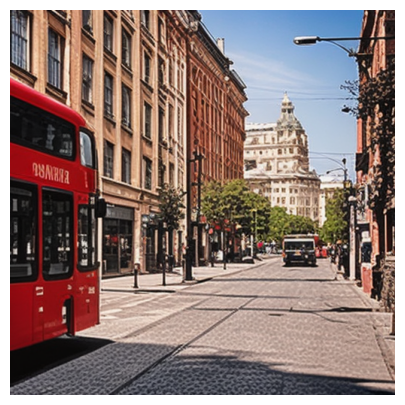

In [3]:
passos = 2
guia = 0.0
prompt = "a red city bus on a sunny street, photo"
foto_gerada = gerar(prompt, semente=0, n_passos=passos)
print("guidance_scale", guia, "| passos", passos, "| tamanho", foto_gerada.size)
plt.figure(figsize=(5, 5))
plt.imshow(foto_gerada)
plt.axis("off")
plt.show()
assert foto_gerada.size == (512, 512)

## A frase manda no assunto

Mesma semente, outro tempo. Se a semente fica e a frase muda, muda o assunto, não o "sorteio" do ruído.

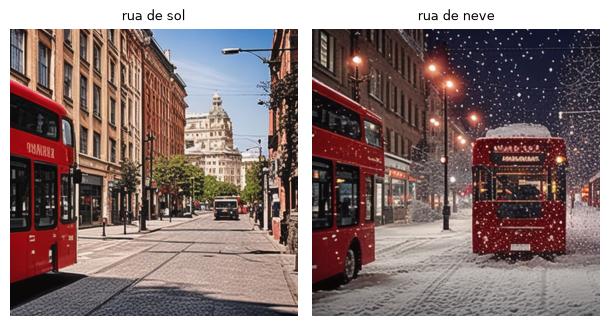

In [4]:
noite = gerar("a red city bus on a snowy street at night, photo", semente=0, n_passos=passos)
grade(
    [foto_gerada, noite],
    ["rua de sol", "rua de neve"],
)

## O que a rede pinta não é o pixel

Por dentro, a rede não mexe nos 512×512×3 números da foto. Ela mexe num latente: uma versão comprimida, com 4 canais e lado 512 dividido por 8. Um decodificador (o VAE) abre isso em pixels no fim. Por isso `in_channels` do UNet é 4, e o agendador ainda conhece os 1000 passos do treino, mesmo quando a gente só anda dois.

In [5]:
print("canais do latente:", pipe.unet.config.in_channels)
print("fator do VAE:", pipe.vae_scale_factor)
print("lado do latente:", 512 // pipe.vae_scale_factor)
print("passos de treino:", pipe.scheduler.config.num_train_timesteps)
print("escala do VAE:", float(pipe.vae.config.scaling_factor))

canais do latente: 4
fator do VAE: 8
lado do latente: 64
passos de treino: 1000
escala do VAE: 0.18215


## Exercícios

Seis perguntas sobre o que acabou de rodar. Escreva a resposta na variável `resposta` e rode a célula. `conferir` diz na hora se fechou. Se travar, abra **Ver solução**.

Rode antes a célula de preparação. Ela só carrega as verificações.

In [ ]:
# @title Preparação dos exercícios (rode, não precisa ler)
from PIL import Image


def _pixels(img):
    return list(img.resize((16, 16)).getdata())


VERIFICAR = {
    1: lambda r: int(r) == foto_gerada.size[0],
    2: lambda r: int(r) == pipe.unet.config.in_channels,
    3: lambda r: int(r) == pipe.scheduler.config.num_train_timesteps,
    4: lambda r: (
        isinstance(r, Image.Image)
        and r.size == (512, 512)
        and _pixels(r) != _pixels(foto_gerada)
    ),
    5: lambda r: int(r) == 512 // pipe.vae_scale_factor,
    6: lambda r: abs(float(r) - float(pipe.vae.config.scaling_factor)) < 1e-4,
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

### Exercício 1. Largura da foto

Quantos pixels de largura tem `foto_gerada`?

<details>
<summary>Ver solução</summary>

```python
resposta = foto_gerada.size[0]
```

</details>

In [ ]:
# Dica: Uma imagem PIL tem .size, que é (largura, altura).
resposta = None

conferir(1, resposta)

### Exercício 2. Canais do latente

O UNet não recebe RGB. Quantos canais tem o latente que entra nele?

<details>
<summary>Ver solução</summary>

```python
resposta = pipe.unet.config.in_channels
```

</details>

In [ ]:
# Dica: pipe.unet.config.in_channels.
resposta = None

conferir(2, resposta)

### Exercício 3. Passos que o treino conhece

O Turbo anda poucos passos na geração, mas o agendador ainda conhece a escala inteira do treino. Quantos passos de treino estão em `pipe.scheduler.config.num_train_timesteps`?

<details>
<summary>Ver solução</summary>

```python
resposta = pipe.scheduler.config.num_train_timesteps
```

</details>

In [ ]:
# Dica: É um inteiro, na casa dos mil.
resposta = None

conferir(3, resposta)

### Exercício 4. Outra semente

Gere de novo o mesmo prompt, com semente 4 e 1 passo. A resposta é a imagem. Ela precisa ter 512×512 e não pode ser a mesma `foto_gerada`.

<details>
<summary>Ver solução</summary>

```python
resposta = gerar(prompt, semente=4, n_passos=1)
```

</details>

In [ ]:
# Dica: gerar(prompt, semente=4, n_passos=1) devolve uma imagem PIL.
resposta = None

conferir(4, resposta)

### Exercício 5. Lado do latente

A rede pinta um quadrado menor, de lado `512 / pipe.vae_scale_factor`. Qual é esse lado, em pixels?

<details>
<summary>Ver solução</summary>

```python
resposta = 512 // pipe.vae_scale_factor
```

</details>

In [ ]:
# Dica: Divisão inteira.
resposta = None

conferir(5, resposta)

### Exercício 6. Escala do VAE

Antes de decodificar, o latente é dividido por `pipe.vae.config.scaling_factor`. Qual é esse número?

<details>
<summary>Ver solução</summary>

```python
resposta = float(pipe.vae.config.scaling_factor)
```

</details>

In [ ]:
# Dica: Converta para float.
resposta = None

conferir(6, resposta)

In [ ]:
placar()

## O que fica

Uma frase, uma semente e poucos passos já devolvem uma foto. O Turbo não usa o botão de volume da frase (`guidance_scale` fica em 0). Quem quiser ver o ruído entrar e sair, passo a passo, olha a ida sem rede e a volta com ela.